# Backpropagation vs Predictive Coding on MNIST
Both networks come from the `src/` package. Run the cells top to bottom.

**Architecture:** 784 → 128 → 64 → 10 (tanh hidden, linear output), MSE on one-hot labels, identical initial weights.

> Data: put `mnist.npz` (Keras format) in `data/`, or run with internet so scikit-learn can download it.

In [1]:
import sys, numpy as np
sys.path.append("..")            # make `src` importable from notebooks/
%matplotlib inline
from src import (load_mnist, BPNet, PCNet, train, accuracy, pc_vs_bp_gradient_similarity,
                 plot_samples, plot_training, plot_layer_energy, plot_predictions)

## 1. Data (MNIST)
Use a subset for speed; set `N_TRAIN = None` for all 60,000 training images.

train (5000, 784) | test (1000, 784) | sizes [784, 128, 64, 10]


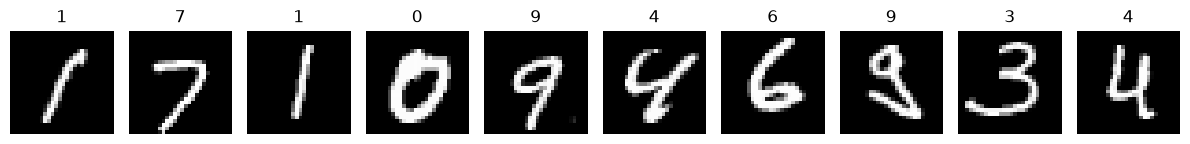

In [3]:
N_TRAIN, N_TEST = 5000, 1000
EPOCHS, LR, BATCH = 20, 0.02, 100   # LR tuned for stability with 784 inputs

ds = load_mnist(n_train=N_TRAIN, n_test=N_TEST)
Xtr, ytr, Ytr, Xte, yte = ds.Xtr, ds.ytr, ds.Ytr, ds.Xte, ds.yte
sizes = [ds.n_in, 128, 64, ds.n_out]
print("train", Xtr.shape, "| test", Xte.shape, "| sizes", sizes)
plot_samples(ds);

## 2. Standard backpropagation

In [4]:
bp = BPNet(sizes, seed=3)
log_bp = train(bp, Xtr, ytr, Ytr, Xte, yte, epochs=EPOCHS, lr=LR, batch_size=BATCH, verbose=5)
print(f"BP  train {log_bp['train_acc'][-1]:.3f} | test {log_bp['test_acc'][-1]:.3f} | time {log_bp['time']:.1f}s")

epoch    5  objective 0.1990  test acc 0.868
epoch   10  objective 0.1517  test acc 0.893
epoch   15  objective 0.1279  test acc 0.916
epoch   20  objective 0.1128  test acc 0.923
BP  train 0.944 | test 0.923 | time 5.8s


## 3. Predictive coding
`PCNet` exposes the pieces separately: `compute_errors` (predictions, layer-wise errors `e_l`, layer-wise energies `F_l`), `infer` (latent-state updates), `total_energy`, and `weight_updates` (local learning).

In [5]:
pc = PCNet(sizes, seed=3, lr_x=0.1, T=30)
log_pc = train(pc, Xtr, ytr, Ytr, Xte, yte, epochs=EPOCHS, lr=LR, batch_size=BATCH, verbose=5)
print(f"PC  train {log_pc['train_acc'][-1]:.3f} | test {log_pc['test_acc'][-1]:.3f} | time {log_pc['time']:.1f}s")

epoch    5  objective 0.1181  test acc 0.786
epoch   10  objective 0.0898  test acc 0.843
epoch   15  objective 0.0750  test acc 0.864
epoch   20  objective 0.0652  test acc 0.878
PC  train 0.902 | test 0.878 | time 57.5s


### 3a. Layer-wise energy, prediction errors and total energy on one batch

Layer-wise energy F_l  (after inference): [0.013256, 0.026653, 0.023306]
Total energy F        : 0.063215
Layer-wise error norms : [0.16282, 0.23088, 0.2159]

step   F1(hid1)   F2(hid2)   F3(out)    total
   0   0.00000   0.00000   0.17989   0.17989
   1   0.00000   0.00236   0.13617   0.13853
   5   0.00049   0.01880   0.06448   0.08377
  20   0.00775   0.02825   0.02881   0.06480
  50   0.01241   0.02699   0.02390   0.06330
 100   0.01326   0.02665   0.02331   0.06322


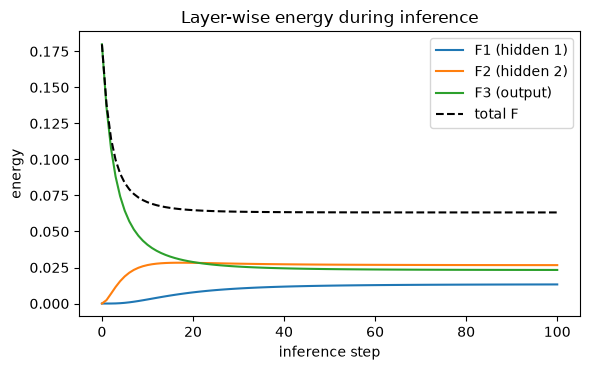

In [6]:
pc_demo = PCNet(sizes, seed=3, lr_x=0.1, T=100)
pc_demo.W = [w.copy() for w in pc.W]; pc_demo.b = [b.copy() for b in pc.b]   # trained weights
xs, As, es, Fl, hist = pc_demo.infer(Xtr[:100], Ytr[:100], record=True)
hist = np.array(hist)

print("Layer-wise energy F_l  (after inference):", [round(float(f), 6) for f in Fl[1:]])
print("Total energy F        :", round(float(sum(Fl[1:])), 6))
print("Layer-wise error norms :", [round(float(np.linalg.norm(e) / np.sqrt(len(e))), 5) for e in es[1:]])
print()
print("step   F1(hid1)   F2(hid2)   F3(out)    total")
for t in [0, 1, 5, 20, 50, 100]:
    print(f"{t:4d}   {hist[t,0]:.5f}   {hist[t,1]:.5f}   {hist[t,-1]:.5f}   {hist[t].sum():.5f}")
plot_layer_energy(hist);

### 3b. Does PC approximate backprop's gradients?
Cosine similarity between PC's local weight updates and −(BP gradient) when the output is only slightly nudged toward the label.

In [8]:
sims = pc_vs_bp_gradient_similarity(sizes, Xtr[:100], Ytr[:100])
for l, s in enumerate(sims): print(f"layer {l}: cosine similarity = {s:.4f}")

layer 0: cosine similarity = 0.9895
layer 1: cosine similarity = 0.9911
layer 2: cosine similarity = 0.9783


## 4. Comparison

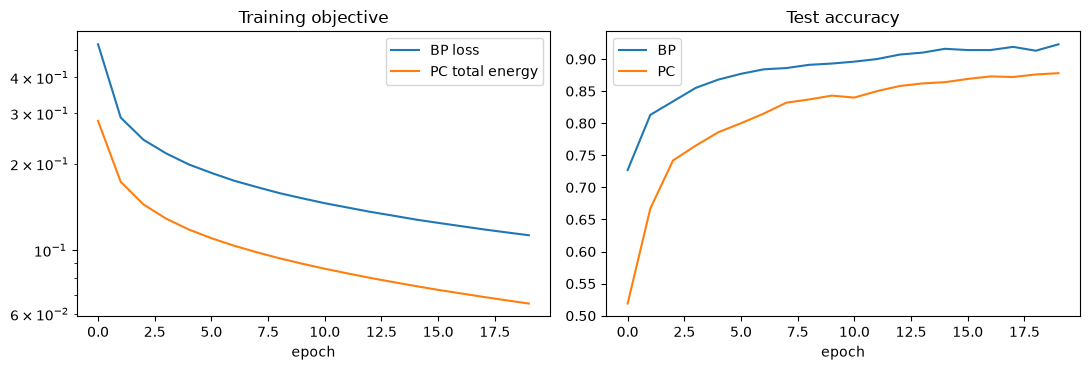

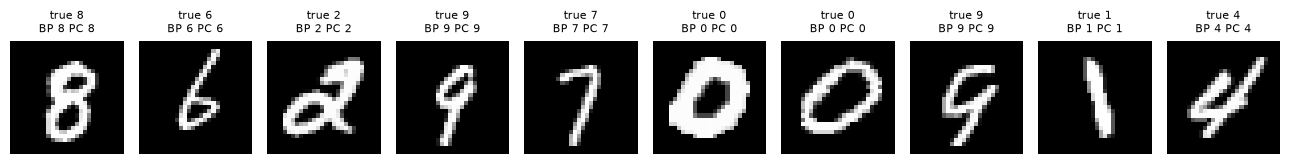

In [9]:
plot_training(log_bp, log_pc);
plot_predictions(bp, pc, ds);

In [10]:
print(f"{'':6}{'train acc':>10}{'test acc':>10}{'objective':>12}{'time (s)':>10}")
for name, lg in (("BP", log_bp), ("PC", log_pc)):
    print(f"{name:6}{lg['train_acc'][-1]:>10.3f}{lg['test_acc'][-1]:>10.3f}{lg['objective'][-1]:>12.4f}{lg['time']:>10.1f}")

       train acc  test acc   objective  time (s)
BP         0.944     0.923      0.1128       5.8
PC         0.902     0.878      0.0652      57.5
